# Face Landmark Selection

This notebook reduces the MediaPipe face landmarks from 468 landmarks to 30 selected landmarks while preserving all pose and hand landmarks.

Selection is learned from `train_X/train_y` only using a supervised tree ensemble. Validation and test data are transformed with the same selected feature mask, but they are not used to choose the mask.

The notebook overwrites the landmark arrays and split pickle files in `landmarks/` once selection succeeds. It also writes one small metadata file, `landmarks/landmark_selection.pkl`, so training and future inference can reproduce the same feature mask.

In [1]:
# from 468 to 30 using sklearn's ExtraTreesClassifier

In [2]:
from pathlib import Path
import pickle
import random
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
try:
    from IPython.display import display
except ImportError:
    display = print


SEED = 42
LANDMARK_DIR = Path('landmarks')
SELECTED_LANDMARK_DIR = Path('selected_landmarks')
SELECTION_METADATA_PATH = SELECTED_LANDMARK_DIR / 'landmark_selection.pkl'

SEQUENCE_LENGTH = 30
NUM_POSE = 33
NUM_FACE = 468
NUM_SELECTED_FACE = 30
NUM_HAND = 21

POSE_FEATURES = NUM_POSE * 3
FACE_FEATURES = NUM_FACE * 3
HAND_FEATURES = NUM_HAND * 3
FULL_FEATURES = POSE_FEATURES + FACE_FEATURES + (2 * HAND_FEATURES)
SELECTED_FEATURES = POSE_FEATURES + (NUM_SELECTED_FACE * 3) + (2 * HAND_FEATURES)

FACE_START_LANDMARK = NUM_POSE
LEFT_HAND_START_LANDMARK = NUM_POSE + NUM_FACE
RIGHT_HAND_START_LANDMARK = LEFT_HAND_START_LANDMARK + NUM_HAND
TOTAL_FULL_LANDMARKS = NUM_POSE + NUM_FACE + (2 * NUM_HAND)

random.seed(SEED)
np.random.seed(SEED)

print('Landmark directory:', LANDMARK_DIR.resolve())
print('Full feature count:', FULL_FEATURES)
print('Selected feature count:', SELECTED_FEATURES)

Landmark directory: D:\Computerpreter\05272026 (third new)\landmarks
Full feature count: 1629
Selected feature count: 315


In [3]:
def load_required_arrays(landmark_dir=LANDMARK_DIR):
    arrays = {}
    for split in ('train', 'val', 'test'):
        arrays[f'{split}_X'] = np.load(landmark_dir / f'{split}_X.npy').astype(np.float32)
        arrays[f'{split}_y'] = np.load(landmark_dir / f'{split}_y.npy').astype(np.int64)

    with open(landmark_dir / 'label_to_id.pkl', 'rb') as f:
        label_to_id = pickle.load(f)

    split_pickles = {}
    for split in ('train', 'val', 'test'):
        path = landmark_dir / f'{split}_landmarks.pkl'
        with open(path, 'rb') as f:
            split_pickles[split] = pickle.load(f)

    return arrays, label_to_id, split_pickles


arrays, label_to_id, split_pickles = load_required_arrays()
id_to_label = {idx: label for label, idx in label_to_id.items()}

for split in ('train', 'val', 'test'):
    print(f"{split}_X:", arrays[f'{split}_X'].shape, f"{split}_y:", arrays[f'{split}_y'].shape)
print('labels:', label_to_id)

train_X: (3113, 30, 1629) train_y: (3113,)
val_X: (536, 30, 1629) val_y: (536,)
test_X: (536, 30, 1629) test_y: (536,)
labels: {'again': 0, 'bad': 1, 'bathroom': 2, 'book': 3, 'bye': 4, "don't know": 5, "don't like": 6, "don't understand": 7, "don't want": 8, 'drink': 9, 'eat': 10, 'family': 11, 'father': 12, 'finish': 13, 'friend': 14, 'go': 15, 'good': 16, 'happy': 17, 'have': 18, 'he': 19, 'hello': 20, 'help': 21, 'home': 22, 'know': 23, 'like': 24, 'me': 25, 'more': 26, 'mother': 27, 'name': 28, 'need': 29, 'no': 30, 'not': 31, 'now': 32, 'play': 33, 'please': 34, 'sad': 35, 'same': 36, 'school': 37, 'sit': 38, 'sorry': 39, 'stop': 40, 'thank you': 41, 'they': 42, 'think': 43, 'tired': 44, 'understand': 45, 'want': 46, 'water': 47, 'we': 48, 'what': 49, 'which': 50, 'who': 51, 'why': 52, 'work': 53, 'yes': 54, 'you': 55}


In [4]:
def validate_input_state(arrays, metadata_path=SELECTION_METADATA_PATH):
    feature_counts = {name: value.shape[-1] for name, value in arrays.items() if name.endswith('_X')}
    sequence_lengths = {name: value.shape[1] for name, value in arrays.items() if name.endswith('_X')}

    if any(length != SEQUENCE_LENGTH for length in sequence_lengths.values()):
        raise ValueError(f'Expected sequence length {SEQUENCE_LENGTH}, got {sequence_lengths}')

    unique_feature_counts = set(feature_counts.values())
    if unique_feature_counts == {FULL_FEATURES}:
        print('Input arrays are full 1629-feature arrays. Selection can proceed.')
        return 'full'

    if unique_feature_counts == {SELECTED_FEATURES} and metadata_path.exists():
        print('Input arrays already appear selected, and landmark_selection.pkl exists.')
        print('Skipping selection prevents accidentally selecting twice.')
        return 'already_selected'

    raise ValueError(
        f'Unexpected feature counts {feature_counts}. Expected all {FULL_FEATURES}, '
        f'or all {SELECTED_FEATURES} with {metadata_path.name} present.'
    )


input_state = validate_input_state(arrays)

Input arrays are full 1629-feature arrays. Selection can proceed.


## Train-Only Face Importance

For each face landmark, this builds compact summary features from the 30-frame sequence: mean, standard deviation, minimum, maximum, range, motion, and detection rate. The selector ranks landmarks with `ExtraTreesClassifier` using training data only.

In [5]:
def face_tensor(X):
    points = X.reshape(X.shape[0], X.shape[1], TOTAL_FULL_LANDMARKS, 3)
    return points[:, :, FACE_START_LANDMARK:FACE_START_LANDMARK + NUM_FACE, :]


def summarize_face_landmarks(X):
    face = face_tensor(X)
    detected = np.any(face != 0, axis=-1).astype(np.float32)

    mean = face.mean(axis=1)
    std = face.std(axis=1)
    min_value = face.min(axis=1)
    max_value = face.max(axis=1)
    value_range = max_value - min_value
    detection_rate = detected.mean(axis=1)[..., None]

    if face.shape[1] > 1:
        motion = np.abs(np.diff(face, axis=1)).mean(axis=1)
    else:
        motion = np.zeros_like(mean)

    per_landmark = np.concatenate(
        [mean, std, min_value, max_value, value_range, motion, detection_rate],
        axis=-1,
    )
    return per_landmark.reshape(X.shape[0], -1).astype(np.float32)


def fit_face_importance(train_X, train_y):
    X_summary = summarize_face_landmarks(train_X)
    model = ExtraTreesClassifier(
        n_estimators=600,
        random_state=SEED,
        class_weight='balanced',
        max_features='sqrt',
        n_jobs=-1,
    )
    model.fit(X_summary, train_y)

    summary_features_per_landmark = X_summary.shape[1] // NUM_FACE
    landmark_scores = model.feature_importances_.reshape(NUM_FACE, summary_features_per_landmark).sum(axis=1)
    selected_face_landmarks = np.argsort(landmark_scores)[::-1][:NUM_SELECTED_FACE]
    selected_face_landmarks = np.sort(selected_face_landmarks).astype(np.int64)
    return model, landmark_scores.astype(np.float32), selected_face_landmarks


if input_state == 'full':
    importance_model, face_scores, selected_face_landmarks = fit_face_importance(arrays['train_X'], arrays['train_y'])
    print('Selected face landmarks:', selected_face_landmarks.tolist())
    display(pd.DataFrame({
        'face_landmark': np.arange(NUM_FACE),
        'importance': face_scores,
        'selected': np.isin(np.arange(NUM_FACE), selected_face_landmarks),
    }).sort_values('importance', ascending=False).head(40))
else:
    with open(SELECTION_METADATA_PATH, 'rb') as f:
        selection_metadata = pickle.load(f)
    selected_face_landmarks = np.asarray(selection_metadata['selected_face_landmarks'], dtype=np.int64)
    face_scores = np.asarray(selection_metadata.get('face_landmark_scores', np.zeros(NUM_FACE)), dtype=np.float32)
    print('Already selected landmarks:', selected_face_landmarks.tolist())

Selected face landmarks: [21, 34, 54, 58, 93, 109, 127, 132, 135, 137, 148, 149, 150, 152, 162, 172, 175, 176, 177, 234, 251, 284, 288, 323, 361, 377, 378, 389, 397, 454]


,face_landmark,importance,selected
127,127,0.002567,True
54,54,0.002550,True
234,234,0.002548,True
93,93,0.002518,True
132,132,0.002504,True
21,21,0.002493,True
162,162,0.002471,True
378,378,0.002460,True
176,176,0.002455,True
454,454,0.002450,True


In [6]:
def build_selected_landmark_indices(selected_face_landmarks):
    pose_indices = np.arange(0, NUM_POSE, dtype=np.int64)
    face_indices = FACE_START_LANDMARK + np.asarray(selected_face_landmarks, dtype=np.int64)
    hand_indices = np.arange(LEFT_HAND_START_LANDMARK, TOTAL_FULL_LANDMARKS, dtype=np.int64)
    return np.concatenate([pose_indices, face_indices, hand_indices]).astype(np.int64)


def landmark_indices_to_feature_indices(landmark_indices):
    feature_indices = []
    for landmark_idx in landmark_indices:
        start = int(landmark_idx) * 3
        feature_indices.extend([start, start + 1, start + 2])
    return np.asarray(feature_indices, dtype=np.int64)


selected_landmark_indices = build_selected_landmark_indices(selected_face_landmarks)
selected_feature_indices = landmark_indices_to_feature_indices(selected_landmark_indices)

print('Selected landmark count:', len(selected_landmark_indices))
print('Selected feature count:', len(selected_feature_indices))
assert len(selected_face_landmarks) == NUM_SELECTED_FACE
assert len(selected_feature_indices) == SELECTED_FEATURES

Selected landmark count: 105
Selected feature count: 315


In [7]:
def transform_arrays_with_selection(arrays, selected_feature_indices):
    transformed = dict(arrays)
    for split in ('train', 'val', 'test'):
        transformed[f'{split}_X'] = arrays[f'{split}_X'][:, :, selected_feature_indices].astype(np.float32)
    return transformed


def evaluate_summary_selector(model, arrays, selected_face_landmarks):
    rows = []
    selected_summary_indices = []
    summary_features_per_landmark = summarize_face_landmarks(arrays['train_X']).shape[1] // NUM_FACE
    for landmark_idx in selected_face_landmarks:
        start = int(landmark_idx) * summary_features_per_landmark
        selected_summary_indices.extend(range(start, start + summary_features_per_landmark))

    for split in ('train', 'val', 'test'):
        X_summary = summarize_face_landmarks(arrays[f'{split}_X'])
        y_true = arrays[f'{split}_y']
        y_pred_all = model.predict(X_summary)

        reduced_model = ExtraTreesClassifier(
            n_estimators=300,
            random_state=SEED,
            class_weight='balanced',
            max_features='sqrt',
            n_jobs=-1,
        )
        reduced_model.fit(
            summarize_face_landmarks(arrays['train_X'])[:, selected_summary_indices],
            arrays['train_y'],
        )
        y_pred_selected = reduced_model.predict(X_summary[:, selected_summary_indices])

        rows.append({
            'split': split,
            'full_face_summary_accuracy': accuracy_score(y_true, y_pred_all),
            'selected_face_summary_accuracy': accuracy_score(y_true, y_pred_selected),
            'count': len(y_true),
        })

    return pd.DataFrame(rows)


if input_state == 'full':
    selected_arrays = transform_arrays_with_selection(arrays, selected_feature_indices)
    display(evaluate_summary_selector(importance_model, arrays, selected_face_landmarks))
    for split in ('train', 'val', 'test'):
        print(f"{split}_X selected shape:", selected_arrays[f'{split}_X'].shape)
else:
    selected_arrays = arrays
    print('Arrays are already selected; no transformation needed.')

,split,full_face_summary_accuracy,selected_face_summary_accuracy,count
0,train,0.955349,0.955349,3113
1,val,0.069030,0.069030,536
2,test,0.054104,0.065299,536


train_X selected shape: (3113, 30, 315)
val_X selected shape: (536, 30, 315)
test_X selected shape: (536, 30, 315)


In [8]:
def save_selected_outputs(output_dir, selected_arrays, split_pickles, label_to_id):
    output_dir.mkdir(parents=True, exist_ok=True)
    
    with open(output_dir / 'label_to_id.pkl', 'wb') as f:
        pickle.dump(label_to_id, f)

    for split in ('train', 'val', 'test'):
        np.save(output_dir / f'{split}_X.npy', selected_arrays[f'{split}_X'])
        np.save(output_dir / f'{split}_y.npy', selected_arrays[f'{split}_y'])

        payload = dict(split_pickles[split])
        payload['X'] = selected_arrays[f'{split}_X']
        payload['y'] = selected_arrays[f'{split}_y']
        payload['label_to_id'] = label_to_id
        payload['landmark_selection_applied'] = True
        
        with open(output_dir / f'{split}_landmarks.pkl', 'wb') as f:
            pickle.dump(payload, f)

def build_selection_metadata():
    return {
        'method': 'ExtraTreesClassifier face-summary feature importance',
        'created_at': datetime.now().isoformat(timespec='seconds'),
        'seed': SEED,
        'sequence_length': SEQUENCE_LENGTH,
        'original_feature_count': FULL_FEATURES,
        'selected_feature_count': SELECTED_FEATURES,
        'num_pose_landmarks': NUM_POSE,
        'num_original_face_landmarks': NUM_FACE,
        'num_selected_face_landmarks': NUM_SELECTED_FACE,
        'num_hand_landmarks_each': NUM_HAND,
        'selected_face_landmarks': selected_face_landmarks.tolist(),
        'selected_landmark_indices': selected_landmark_indices.tolist(),
        'selected_feature_indices': selected_feature_indices.tolist(),
        'face_landmark_scores': face_scores.tolist(),
        'label_to_id': label_to_id,
    }

if input_state == 'full':
    output_dir = SELECTED_LANDMARK_DIR
    
    save_selected_outputs(output_dir, selected_arrays, split_pickles, label_to_id)
    
    selection_metadata = build_selection_metadata()
    with open(SELECTION_METADATA_PATH, 'wb') as f:
        pickle.dump(selection_metadata, f)
        
    print('Put selected landmark arrays and split pickle files in:', output_dir.resolve())
    print('Wrote selection metadata:', SELECTION_METADATA_PATH.resolve())
else:
    print('No files put because selection was already applied.')

Put selected landmark arrays and split pickle files in: D:\Computerpreter\05272026 (third new)\selected_landmarks
Wrote selection metadata: D:\Computerpreter\05272026 (third new)\selected_landmarks\landmark_selection.pkl


In [9]:
arrays_after, label_to_id_after, _ = load_required_arrays(SELECTED_LANDMARK_DIR)

for split in ('train', 'val', 'test'):
    X = arrays_after[f'{split}_X']
    y = arrays_after[f'{split}_y']
    print(f'{split}_X:', X.shape, f'{split}_y:', y.shape)
    if X.shape[-1] != SELECTED_FEATURES:
        raise ValueError(f'{split}_X should have {SELECTED_FEATURES} features after selection, got {X.shape[-1]}')

if len(label_to_id_after) != 56:
    raise ValueError(f'Expected exactly 56 classes, got {label_to_id_after}')

with open(SELECTION_METADATA_PATH, 'rb') as f:
    metadata_after = pickle.load(f)

if len(metadata_after['selected_face_landmarks']) != NUM_SELECTED_FACE:
    raise ValueError('Selection metadata does not contain exactly 30 face landmarks.')

print('Selection verification passed.')

train_X: (3113, 30, 315) train_y: (3113,)
val_X: (536, 30, 315) val_y: (536,)
test_X: (536, 30, 315) test_y: (536,)
Selection verification passed.


The following cell is for visualization.

train_X: (3113, 30, 315) train_y: (3113,)


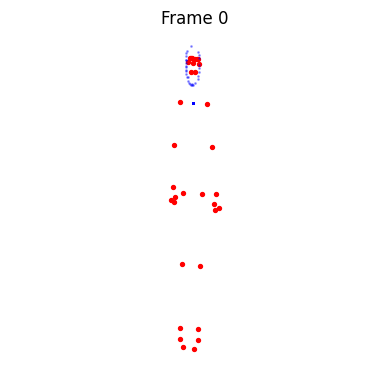

val_X: (536, 30, 315) val_y: (536,)


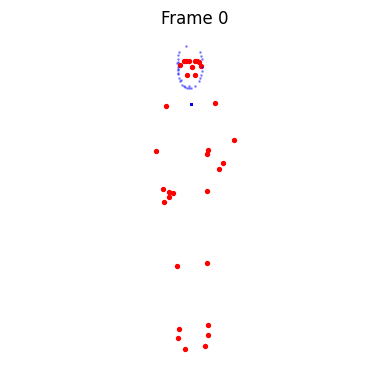

test_X: (536, 30, 315) test_y: (536,)


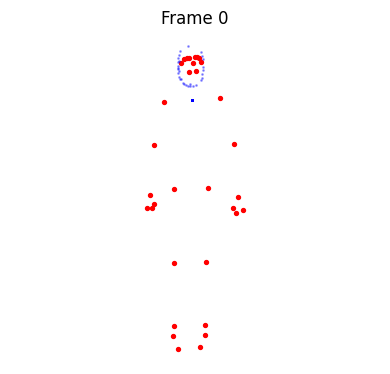

labels: {'again': 0, 'bad': 1, 'bathroom': 2, 'book': 3, 'bye': 4, "don't know": 5, "don't like": 6, "don't understand": 7, "don't want": 8, 'drink': 9, 'eat': 10, 'family': 11, 'father': 12, 'finish': 13, 'friend': 14, 'go': 15, 'good': 16, 'happy': 17, 'have': 18, 'he': 19, 'hello': 20, 'help': 21, 'home': 22, 'know': 23, 'like': 24, 'me': 25, 'more': 26, 'mother': 27, 'name': 28, 'need': 29, 'no': 30, 'not': 31, 'now': 32, 'play': 33, 'please': 34, 'sad': 35, 'same': 36, 'school': 37, 'sit': 38, 'sorry': 39, 'stop': 40, 'thank you': 41, 'they': 42, 'think': 43, 'tired': 44, 'understand': 45, 'want': 46, 'water': 47, 'we': 48, 'what': 49, 'which': 50, 'who': 51, 'why': 52, 'work': 53, 'yes': 54, 'you': 55}


In [10]:
def visualize_landmarks_sequence(sequence, title='', num_frames=5):
    frame_indices = np.linspace(0, len(sequence) - 1, num_frames, dtype=int)
    fig, axes = plt.subplots(1, num_frames, figsize=(4 * num_frames, 4))
    if num_frames == 1:
        axes = [axes]

    for ax, frame_idx in zip(axes, frame_indices):
        frame = sequence[frame_idx]
        points = frame.reshape(-1, 3)

        pose = points[:NUM_POSE]
        face = points[NUM_POSE:NUM_POSE + NUM_FACE]
        left_hand = points[NUM_POSE + NUM_FACE:NUM_POSE + NUM_FACE + NUM_HAND]
        right_hand = points[NUM_POSE + NUM_FACE + NUM_HAND:]

        ax.scatter(pose[:, 0], -pose[:, 1], c='red', s=8, label='pose')
        ax.scatter(face[:, 0], -face[:, 1], c='blue', s=1, alpha=0.35, label='face')
        ax.scatter(left_hand[:, 0], -left_hand[:, 1], c='green', s=8, label='left hand')
        ax.scatter(right_hand[:, 0], -right_hand[:, 1], c='purple', s=8, label='right hand')
        ax.set_title(f'Frame {frame_idx}')
        ax.axis('equal')
        ax.axis('off')

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


sample_idx = 0
arrays, label_to_id, split_pickles = load_required_arrays(SELECTED_LANDMARK_DIR)
id_to_label = {idx: label for label, idx in label_to_id.items()}

for split in ('train', 'val', 'test'):
    print(f"{split}_X:", arrays[f'{split}_X'].shape, f"{split}_y:", arrays[f'{split}_y'].shape)
    visualize_landmarks_sequence(arrays[f'{split}_X'][sample_idx], num_frames=1)
print('labels:', label_to_id)

## Next Step

`train_model.ipynb` should load the arrays from `selected_landmarks/`, keep `landmark_selection.pkl` in the saved model checkpoint, and use the label map emitted by the current landmark extraction run. `asl_detector.py` must also apply `selected_feature_indices` at inference time before feeding landmarks into a model trained on the reduced 315-feature representation.